In [1]:
# ================================================
# PROJECT: AIR TEMPERATURE TIME SERIES FORECASTING
# PROJECT ID: PRAICP-1003-AirTempTS
# ================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import warnings

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

warnings.filterwarnings('ignore')

In [2]:
# 2. EXTRACT DATASET

zip_path = 'PRAICP-1003-AirTempTS.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
# 3. LOAD DATASET

csv_path = os.path.join(
    'dataset',
    'Data',
    'surface-air-temperature-monthly-mean.csv'
)

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
# 4. DISPLAY FIRST FIVE RECORDS

print("\nFirst Five Records:")
display(df.head())


First Five Records:


,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


In [5]:
# 5. DATASET INFORMATION

print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      462 non-null    object 
 1   mean_temp  462 non-null    float64
dtypes: float64(1), object(1)
memory usage: 7.3+ KB


In [6]:
# 6. CHECK DATASET DIMENSIONS

print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(462, 2)


In [7]:
# 7. STATISTICAL SUMMARY

print("\nStatistical Summary:")
display(df.describe())


Statistical Summary:


,mean_temp
count,462.000000
mean,27.665152
std,0.808186
min,25.400000
25%,27.100000
50%,27.700000
75%,28.300000
max,29.500000


In [8]:
# 8. CHECK MISSING VALUES

print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
month        0
mean_temp    0
dtype: int64


In [9]:
# 9. CHECK DUPLICATE RECORDS

print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


In [10]:
# 10. DATA PREPROCESSING

df['month'] = pd.to_datetime(df['month'])

df['mean_temp'] = pd.to_numeric(
    df['mean_temp'],
    errors='coerce'
)

df = df.dropna(subset=['month', 'mean_temp'])

df = df.sort_values('month')

df = df.drop_duplicates(
    subset=['month'],
    keep='last'
)

df = df.set_index('month')

# Set monthly frequency
df = df.asfreq('MS')

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

# Fill missing monthly observations if any
df['mean_temp'] = df['mean_temp'].interpolate(
    method='time'
)

print("\nPrepared Dataset:")
display(df.head())


Missing values after preprocessing:
mean_temp    0
dtype: int64

Prepared Dataset:


,mean_temp
month,
1982-01-01,25.9
1982-02-01,27.1
1982-03-01,27.2
1982-04-01,27.0
1982-05-01,28.0


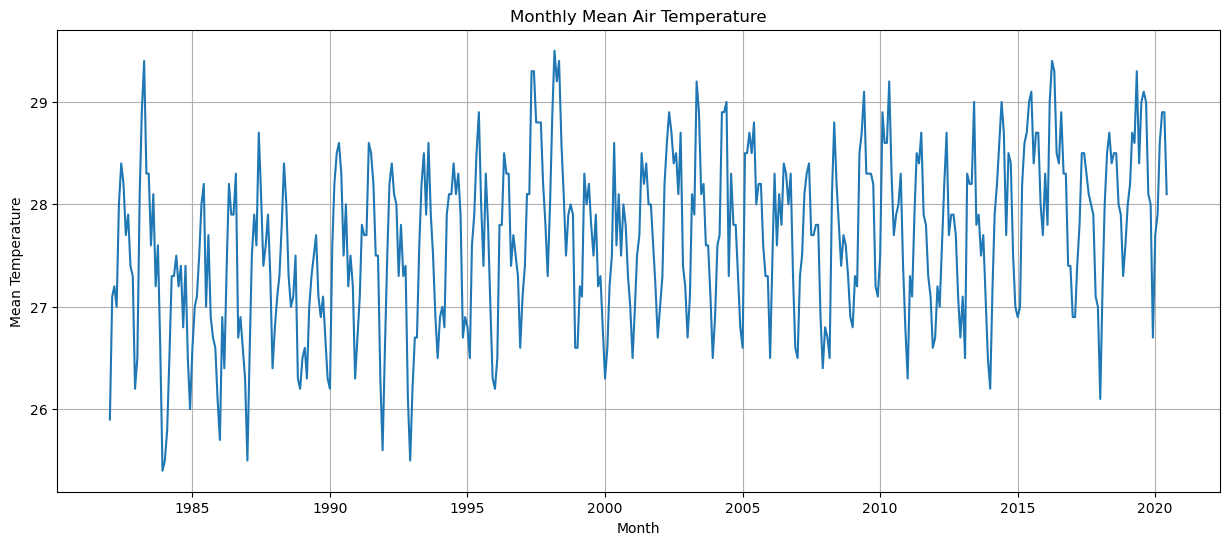

In [11]:
# 11. EXPLORATORY DATA ANALYSIS

# Monthly Mean Temperature Trend

plt.figure(figsize=(15, 6))

plt.plot(df.index, df['mean_temp'])

plt.title('Monthly Mean Air Temperature')
plt.xlabel('Month')
plt.ylabel('Mean Temperature')

plt.grid(True)
plt.show()


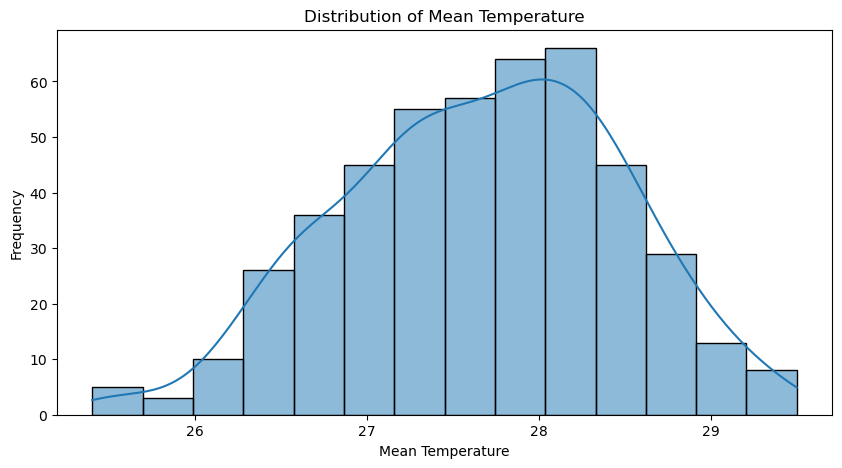

In [12]:
# 12. TEMPERATURE DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    df['mean_temp'],
    kde=True
)

plt.title('Distribution of Mean Temperature')
plt.xlabel('Mean Temperature')
plt.ylabel('Frequency')

plt.show()

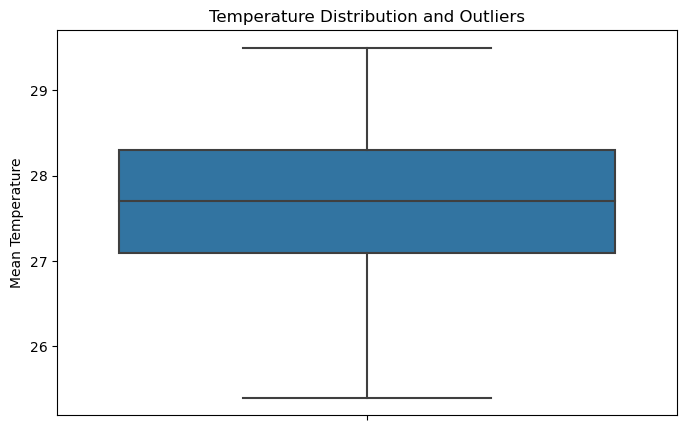

In [13]:
# 13. BOX PLOT

plt.figure(figsize=(8, 5))

sns.boxplot(y=df['mean_temp'])

plt.title('Temperature Distribution and Outliers')
plt.ylabel('Mean Temperature')

plt.show()

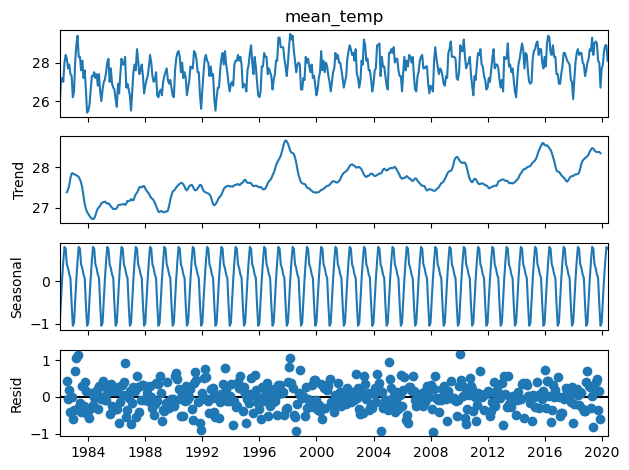

In [14]:
# 14. TIME SERIES DECOMPOSITION

decomposition = seasonal_decompose(
    df['mean_temp'],
    model='additive',
    period=12
)

decomposition.plot()

plt.show()

In [15]:
# 15. STATIONARITY TEST

result = adfuller(df['mean_temp'])

print("ADF Statistic:", result[0])
print("P-value:", result[1])

if result[1] <= 0.05:
    print("The series is stationary.")
else:
    print("The series is non-stationary.")

ADF Statistic: -4.26504639536064
P-value: 0.0005103681123778952
The series is stationary.


In [16]:
# 16. TRAIN AND TEST SPLIT

train_size = int(len(df) * 0.80)

train = df['mean_temp'].iloc[:train_size]
test = df['mean_temp'].iloc[train_size:]

print("\nTraining Records:", len(train))
print("Testing Records:", len(test))



Training Records: 369
Testing Records: 93


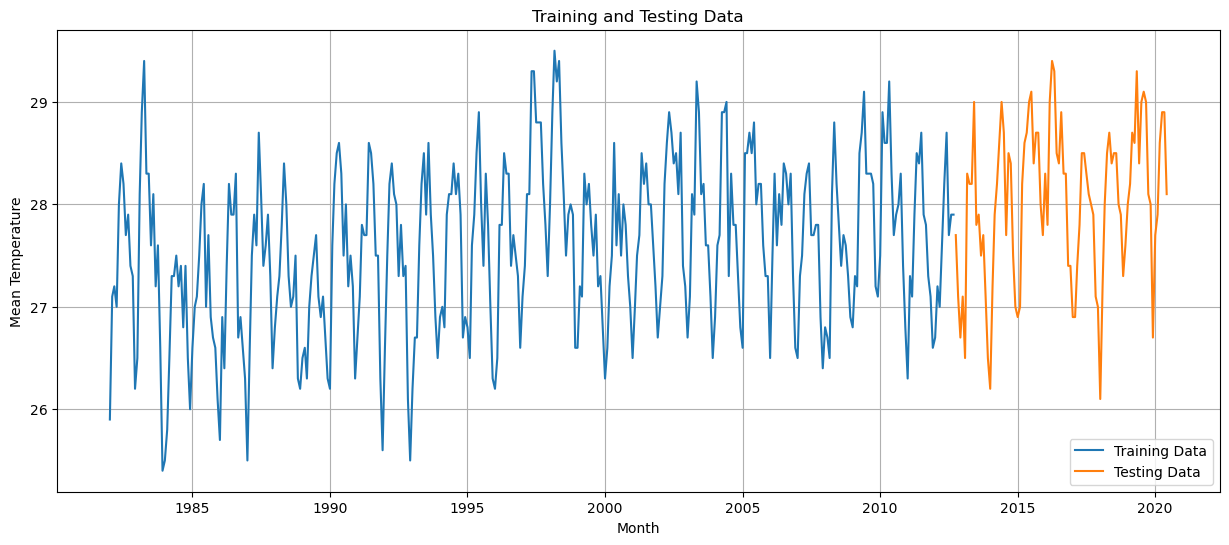

In [17]:
# 17. VISUALIZE TRAINING AND TESTING DATA

plt.figure(figsize=(15, 6))

plt.plot(train, label='Training Data')
plt.plot(test, label='Testing Data')

plt.title('Training and Testing Data')
plt.xlabel('Month')
plt.ylabel('Mean Temperature')

plt.legend()
plt.grid(True)
plt.show()


In [18]:
# 18. SEASONAL NAIVE BASELINE MODEL

seasonal_predictions = np.tile(
    train.values[-12:],
    int(np.ceil(len(test) / 12))
)[:len(test)]

seasonal_predictions = pd.Series(
    seasonal_predictions,
    index=test.index
)


In [19]:
# 19. BUILD SARIMA MODEL

model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_result = model.fit(disp=False)

print("\nSARIMA Model Summary:")
print(model_result.summary())


SARIMA Model Summary:
                                     SARIMAX Results                                      
Dep. Variable:                          mean_temp   No. Observations:                  369
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -188.694
Date:                            Fri, 06 Nov 2026   AIC                            387.389
Time:                                    17:15:48   BIC                            406.563
Sample:                                01-01-1982   HQIC                           395.027
                                     - 09-01-2012                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2675      0.068      3.922      0.000       0.134       0.401
ma.L1       

In [20]:
# 20. PREDICT TEST DATA

predictions = model_result.forecast(
    steps=len(test)
)

predictions = pd.Series(
    predictions.values,
    index=test.index
)


In [21]:
# 21. MODEL EVALUATION

def evaluate_model(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(mse)

    mape = mean_absolute_percentage_error(
        actual,
        predicted
    ) * 100

    print("MAE:", round(mae, 4))
    print("MSE:", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("MAPE:", round(mape, 4), "%")


print("\nSEASONAL NAIVE MODEL PERFORMANCE")

evaluate_model(
    test,
    seasonal_predictions
)


print("\nSARIMA MODEL PERFORMANCE")

evaluate_model(
    test,
    predictions
)



SEASONAL NAIVE MODEL PERFORMANCE
MAE: 0.6452
MSE: 0.634
RMSE: 0.7962
MAPE: 2.2795 %

SARIMA MODEL PERFORMANCE
MAE: 0.5297
MSE: 0.4372
RMSE: 0.6612
MAPE: 1.874 %


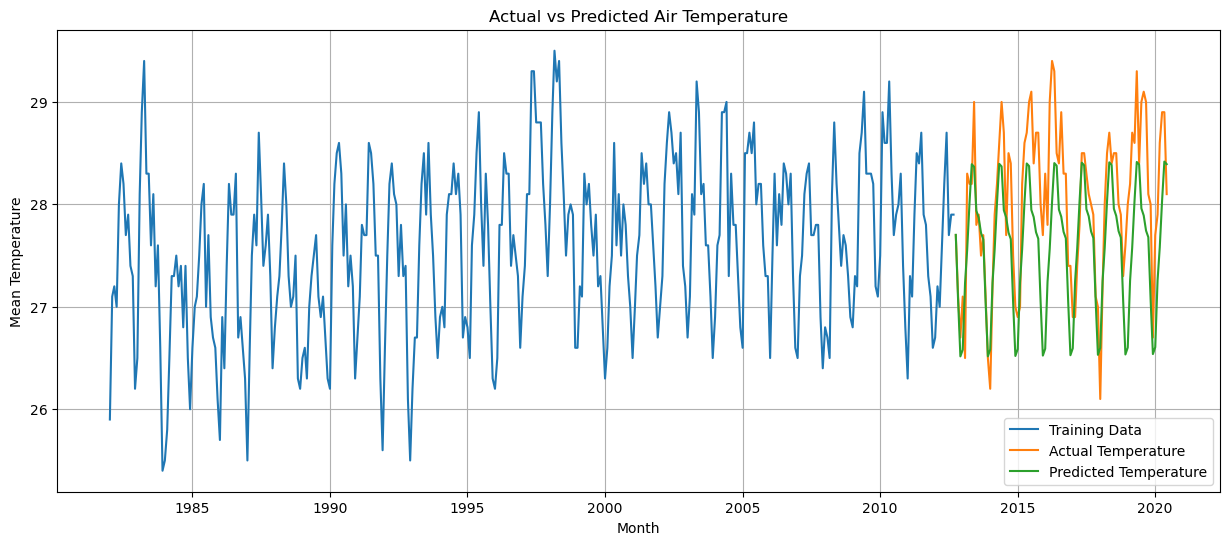

In [22]:
# 22. ACTUAL VS PREDICTED TEMPERATURE

plt.figure(figsize=(15, 6))

plt.plot(
    train,
    label='Training Data'
)

plt.plot(
    test,
    label='Actual Temperature'
)

plt.plot(
    predictions,
    label='Predicted Temperature'
)

plt.title('Actual vs Predicted Air Temperature')
plt.xlabel('Month')
plt.ylabel('Mean Temperature')

plt.legend()
plt.grid(True)

plt.show()

In [23]:
# 23. COMPARE MODEL PERFORMANCE

results = pd.DataFrame({
    'Actual': test,
    'Seasonal_Naive': seasonal_predictions,
    'SARIMA': predictions
})

print("\nModel Prediction Comparison:")
display(results.head(15))


Model Prediction Comparison:


,Actual,Seasonal_Naive,SARIMA
month,,,
2012-10-01,27.7,27.3,27.702716
2012-11-01,27.1,27.1,27.052331
2012-12-01,26.7,26.6,26.516137
2013-01-01,27.1,26.7,26.581088
2013-02-01,26.5,27.2,27.233508
2013-03-01,28.3,27.0,27.555256
2013-04-01,28.2,27.6,28.012137
2013-05-01,28.2,28.2,28.391946
2013-06-01,29.0,28.7,28.366764


In [24]:
# 24. TRAIN FINAL MODEL USING COMPLETE DATASET

final_model = SARIMAX(
    df['mean_temp'],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_result = final_model.fit(disp=False)

In [25]:
# 25. FORECAST NEXT 12 MONTHS

future_forecast = final_result.get_forecast(
    steps=12
)

forecast_values = future_forecast.predicted_mean

confidence_intervals = future_forecast.conf_int()

forecast_df = pd.DataFrame({
    'Month': forecast_values.index,
    'Predicted_Mean_Temperature': forecast_values.values,
    'Lower_Bound': confidence_intervals.iloc[:, 0].values,
    'Upper_Bound': confidence_intervals.iloc[:, 1].values
})

print("\nNEXT 12 MONTHS AIR TEMPERATURE FORECAST:")

display(forecast_df)


NEXT 12 MONTHS AIR TEMPERATURE FORECAST:


,Month,Predicted_Mean_Temperature,Lower_Bound,Upper_Bound
0,2020-07-01,28.335973,27.532927,29.139018
1,2020-08-01,28.370118,27.503377,29.236859
2,2020-09-01,28.246881,27.349775,29.143987
3,2020-10-01,28.177888,27.255929,29.099848
4,2020-11-01,27.557775,26.612447,28.503103
5,2020-12-01,27.060705,26.092732,28.028678
6,2021-01-01,27.137006,26.146936,28.127075
7,2021-02-01,27.690531,26.678918,28.702143
8,2021-03-01,28.147544,27.114763,29.180325
9,2021-04-01,28.559924,27.506418,29.613429


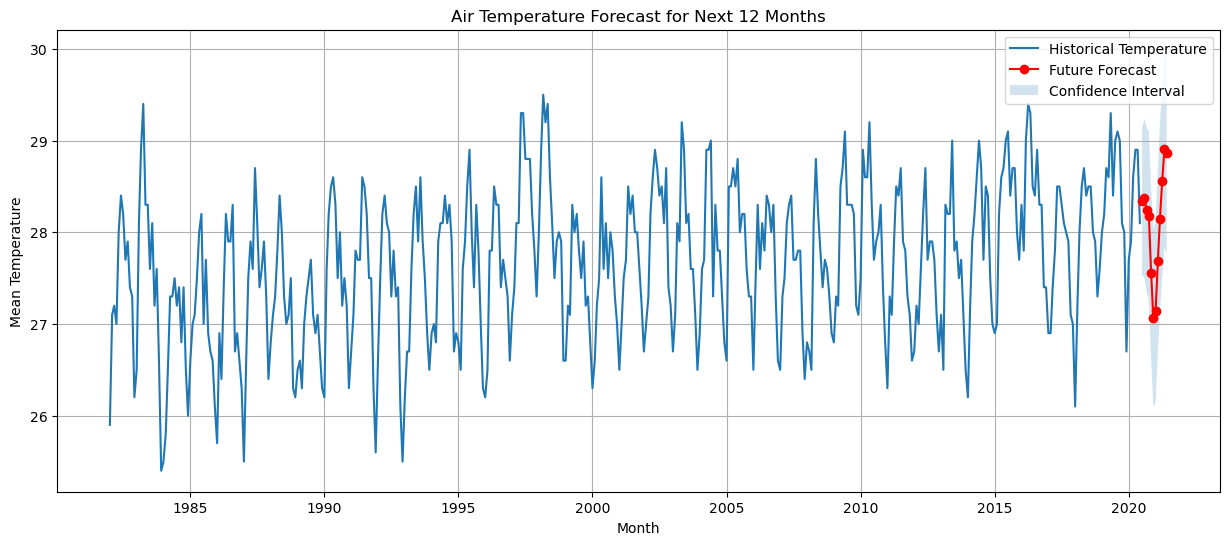

In [26]:
# 26. VISUALIZE FUTURE FORECAST

plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df['mean_temp'],
    label='Historical Temperature'
)

plt.plot(
    forecast_values.index,
    forecast_values.values,
    color='red',
    marker='o',
    label='Future Forecast'
)

plt.fill_between(
    forecast_values.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label='Confidence Interval'
)

plt.title('Air Temperature Forecast for Next 12 Months')
plt.xlabel('Month')
plt.ylabel('Mean Temperature')

plt.legend()
plt.grid(True)

plt.show()


In [27]:
# 27. SAVE FORECAST RESULTS

forecast_df.to_csv(
    'Air_Temperature_Forecast.csv',
    index=False
)

print("\nForecast results saved successfully!")


Forecast results saved successfully!


In [28]:
# 28. FINAL PROJECT CONCLUSION

print("""
PROJECT COMPLETED!

Project: Air Temperature Time Series Forecasting

Objective:
To develop a Machine Learning model
to forecast monthly mean air temperature.

The project includes:
1. Dataset Loading
2. Data Preprocessing
3. Exploratory Data Analysis
4. Time Series Analysis
5. Model Building
6. Model Evaluation
7. Future Temperature Forecasting
8. Saving Forecast Results
""")


PROJECT COMPLETED!

Project: Air Temperature Time Series Forecasting

Objective:
To develop a Machine Learning model
to forecast monthly mean air temperature.

The project includes:
1. Dataset Loading
2. Data Preprocessing
3. Exploratory Data Analysis
4. Time Series Analysis
5. Model Building
6. Model Evaluation
7. Future Temperature Forecasting
8. Saving Forecast Results

